# Supplementary Figure 6

Panels a-c test how much FastaLake identification depends on selecting the database from the same spectra that are scored: databases selected from all, odd-scan or even-scan predictions were searched against the same odd-scan spectra (726 acquisitions, peptides of 9-50 residues). Panels d,e compare public-sequence FastaLake with the matched metagenome search on the same spectra (296 PREDICT and 282 CapScan acquisitions, 9-50 residues). All five panels are drawn on one canvas, as in the v30 build.

Run from the repository root with `python paper.py build SFig06`. Pixel checks need the Söhne fonts (`FASTALAKE_FONT_DIR`).

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()
import os, json
import pandas as pd
from IPython.display import Image, display
d726 = panels.load_split()
bench = panels.load_benchmark()

## Figure

All panels are drawn on one 180 x 186 mm canvas (`panels.figure`, which calls `panel_a`, `panel_bc` and `panel_de`). The d,e inputs are parameters (`panels.BENCH_TABLES`, `panels.BENCH_N`) because the CapScan metagenome benchmark is being extended to 295 acquisitions.

  [style] SFig06: 0 label(s) raised to 5 pt, 5 capped to 7 pt, 0 tick axis/axes clamped, 578 line(s) raised to 1 pt


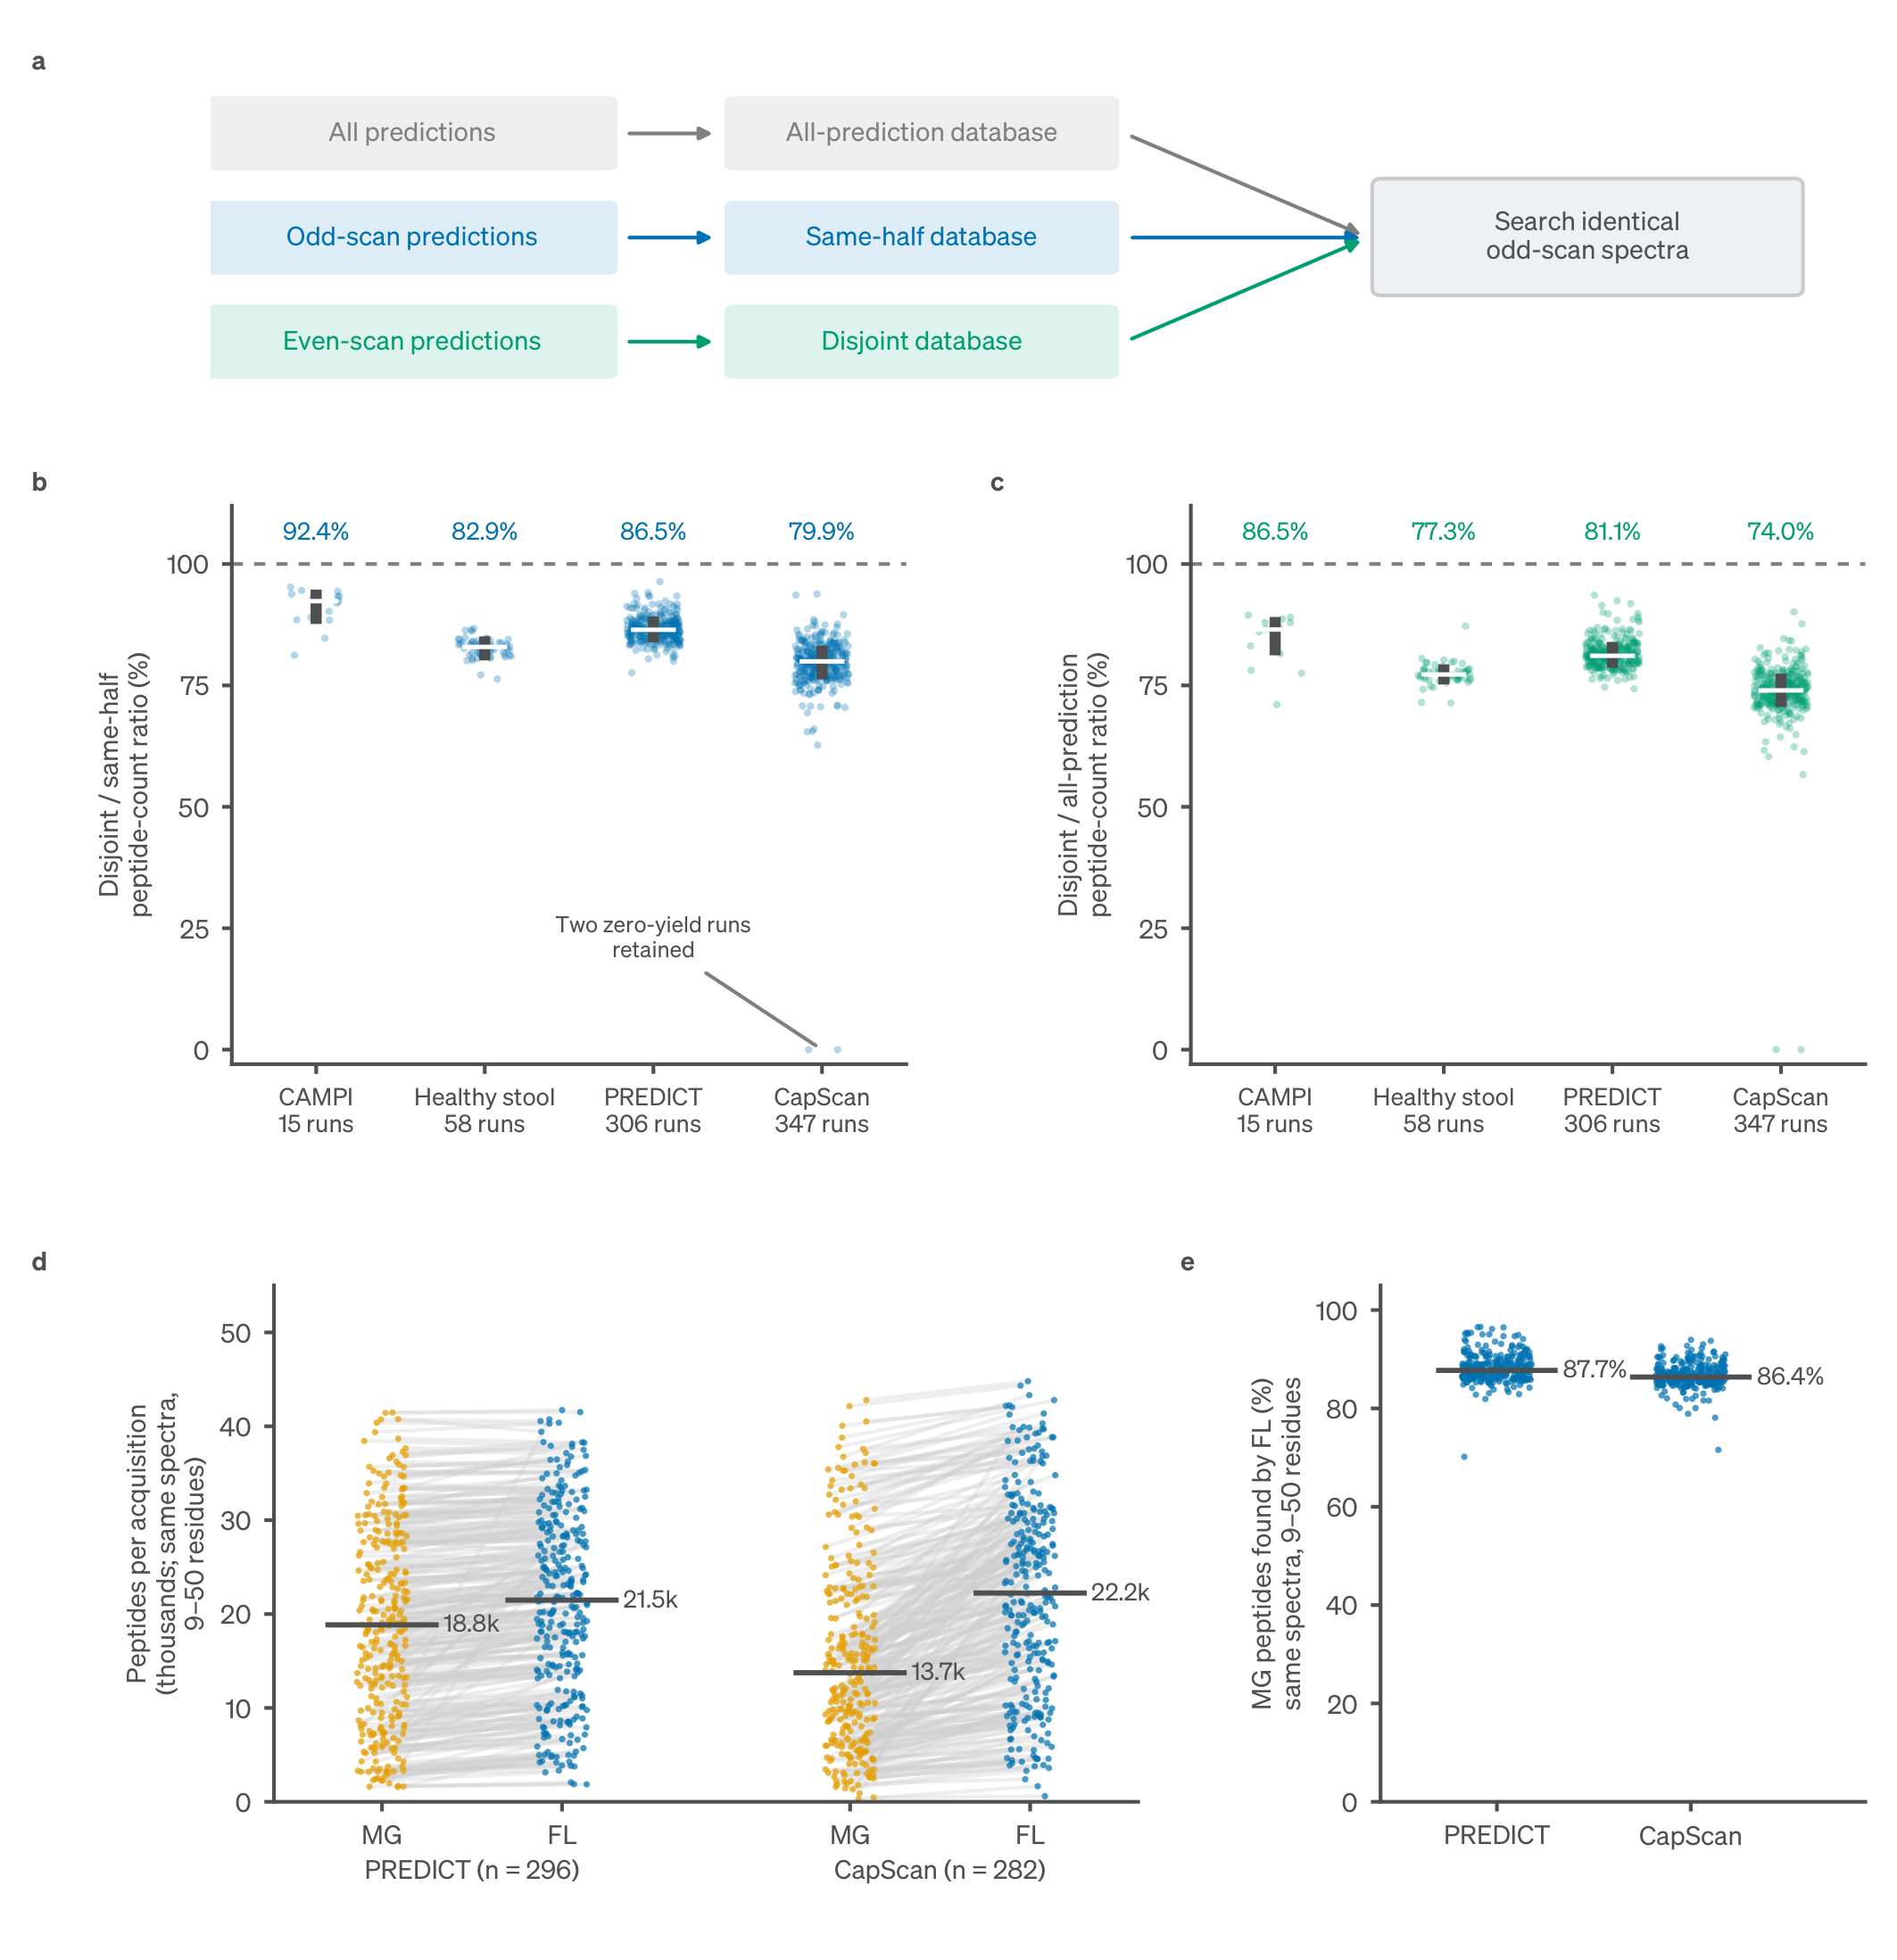

In [2]:
fig_out = panels.figure(OUT)
display(Image(filename=str(fig_out["png"]), width=760))

## Panel a

Schematic of the spectrum-split experiment: all predictions select the all-prediction database, odd-scan predictions the same-half database and even-scan predictions the disjoint database; all three are searched against the identical odd-scan MS2 spectra (visible_v30f line 49, "we selected protein databases using all predictions, odd-scan predictions or even-scan predictions, and searched the same odd-scan spectra against each database"). No data and no test. Drawn in the canvas above.

## Panel b

Disjoint/same-half peptide-count ratio per acquisition, 9-50 residues (visible_v30f line 49, "the median ratios of peptide counts with disjoint selection to those with same-half selection were 92.4% in CAMPI, 82.9% in healthy stool, 86.5% in PREDICT and 79.9% in CapScan"). n = 726 acquisitions (15 CAMPI, 58 healthy stool, 306 PREDICT, 347 CapScan). Bars: median and interquartile range; no test. Acquisitions are nested in participants (printed below from `split_half_structure.tsv`). Drawn in the canvas above.

In [3]:
summ = panels.stat_split_summary(d726)
print((100 * summ[["median_D_over_S", "q25_D_over_S", "q75_D_over_S"]]).to_string())
print(summ[["n", "D_lower_S", "zero_disjoint"]].to_string())
print(panels.load_structure().to_string())   # acquisitions nested in participants (STATS.tsv)

            median_D_over_S  q25_D_over_S  q75_D_over_S
cohort                                                 
CAMPI_MOCK        92.350333     88.799764     93.592189
HSTOOL            82.924190     81.310446     83.947445
PREDICT           86.467991     85.037617     88.049414
CAPSCAN           79.947288     77.384682     82.019117
              n  D_lower_S  zero_disjoint
cohort                                   
CAMPI_MOCK   15         15              0
HSTOOL       58         58              0
PREDICT     306        306              0
CAPSCAN     347        347              2
            n_acquisitions  n_participants  n_specimens  n_acquisitions_without_participant  n_acquisitions_without_specimen
cohort                                                                                                                      
HSTOOL                  58               0            0                                  58                               58
CAMPI_MOCK              15           

## Panel c

Disjoint/all-prediction peptide-count ratio per acquisition, 9-50 residues; same acquisitions as b (n = 726). Bars: median and interquartile range; no test. Drawn in the canvas above.

In [4]:
print((100 * summ[["median_D_over_F", "q25_D_over_F", "q75_D_over_F"]]).to_string())

            median_D_over_F  q25_D_over_F  q75_D_over_F
cohort                                                 
CAMPI_MOCK        86.508396     82.356263     87.955698
HSTOOL            77.253654     76.351678     78.191822
PREDICT           81.097057     79.777769     82.809735
CAPSCAN           73.965281     71.749092     76.281819


## Panel d

Peptides of 9-50 residues per acquisition in the matched metagenome (MG) and public-sequence FastaLake (FL) searches of the same spectra, FastaLake databases selected from the scored spectra (visible_v30f line 64, "FastaLake identified a median 9.4% more 9–50-residue peptides than the metagenome search, with higher counts in 272 acquisitions"; line 65, "a median 42.4% more 9–50-residue peptides ... with higher counts in 281 acquisitions"). n = 296 PREDICT and 282 CapScan acquisitions. Lines pair acquisitions, bars are medians; no test. Drawn in the canvas above.

In [5]:
b = panels.stat_bench(bench)
print(json.dumps({k: {kk: b[k][kk] for kk in ("n", "median_MG", "median_FL", "n_FL_gt_MG", "median_gain_pct")} for k in b}, indent=1))

{
 "PREDICT": {
  "n": 296,
  "median_MG": 18847.0,
  "median_FL": 21483.5,
  "n_FL_gt_MG": 272,
  "median_gain_pct": 9.386055289278694
 },
 "CAPSCAN": {
  "n": 282,
  "median_MG": 13746.0,
  "median_FL": 22237.0,
  "n_FL_gt_MG": 281,
  "median_gain_pct": 42.44817334707096
 }
}


## Panel e

Fraction of metagenome-search peptide identities (9-50 residues) also identified by FastaLake in the same acquisition (visible_v30f line 64, "recovering 87.7% of metagenome-search peptide identities"; line 65, "recovering 86.4%"). n = 296 PREDICT and 282 CapScan acquisitions; bars are medians; no test. Drawn in the canvas above.

In [6]:
print({k: b[k]["median_recovery_pct"] for k in b})

{'PREDICT': 87.73245932485992, 'CAPSCAN': 86.37261339225655}


## Checks and numbers

Pixel check of the figure against the v30 render in `expected/`, the plotted values of d,e against the v30 build's table, then every number of `NUMBERS.tsv` in file order.

In [7]:
from tools.check_pixels import compare
E, K = UNIT / "expected", UNIT / "checks"
if not panels.font_dir():
    print("pixel checks SKIPPED: fonts absent")
else:
    r = compare(fig_out["png"], E / "SFig06_v30.png", K / "SFig06_v30", dpi=300)
    print(f"SFig06_v30 {r['verdict']:10} differing pixels {r.get('differing_pixels')}")
pv_new = pd.read_csv(fig_out["plotted_values"], sep="\t")
pv_old = pd.read_csv(E / "panel_de_plotted_values.tsv", sep="\t")
print("panel d,e plotted values equal to v30 table:", pv_new.equals(pv_old))

t = panels.stat_split_text(d726)
assert t["all_fewer"]   # line 49: fewer accepted peptides in every acquisition
numbers = [   # NUMBERS.tsv order; keys name the v30 paragraph (v30_para)
    ("49 n acquisitions", t["n_total"]),
    ("49 D/S CAMPI %", t["median_DS_pct"]["CAMPI_MOCK"]),
    ("49 D/S healthy stool %", t["median_DS_pct"]["HSTOOL"]),
    ("49 D/S PREDICT %", t["median_DS_pct"]["PREDICT"]),
    ("49 D/S CapScan %", t["median_DS_pct"]["CAPSCAN"]),
    ("49 identity retention min %", t["retention_min_pct"]),
    ("49 identity retention max %", t["retention_max_pct"]),
    ("64 PREDICT matched n", b["PREDICT"]["n"]),
    ("64 PREDICT median gain %", b["PREDICT"]["median_gain_pct"]),
    ("64 PREDICT n FL > MG", b["PREDICT"]["n_FL_gt_MG"]),
    ("64 PREDICT recovery %", b["PREDICT"]["median_recovery_pct"]),
    ("64 PREDICT loss with disjoint selection %", t["loss_pct"]["PREDICT"]),
    ("64 CapScan loss with disjoint selection %", t["loss_pct"]["CAPSCAN"]),
    ("65 CapScan matched n", b["CAPSCAN"]["n"]),
    ("65 CapScan median gain %", b["CAPSCAN"]["median_gain_pct"]),
    ("65 CapScan recovery %", b["CAPSCAN"]["median_recovery_pct"]),
    ("231 n acquisitions retained", t["n_total"]),
    ("231 CapScan disjoint zeros", panels.as_word(t["n_capscan_zero_disjoint"])),
    ("65 CapScan n FL > MG", b["CAPSCAN"]["n_FL_gt_MG"]),
    ("231 CAMPI n", t["n_by_cohort"]["CAMPI_MOCK"]),
    ("231 healthy stool n", t["n_by_cohort"]["HSTOOL"]),
    ("231 PREDICT n", t["n_by_cohort"]["PREDICT"]),
    ("231 CapScan n", t["n_by_cohort"]["CAPSCAN"]),
    ("231 d,e PREDICT n", b["PREDICT"]["n"]),
    ("231 d,e CapScan n", b["CAPSCAN"]["n"]),
]
for k, v in numbers:
    print(f"{k:45} {v!r}")

SFig06_v30 IDENTICAL  differing pixels 0
panel d,e plotted values equal to v30 table: True
49 n acquisitions                             726
49 D/S CAMPI %                                92.35033259423504
49 D/S healthy stool %                        82.92418968145265
49 D/S PREDICT %                              86.46799130885695
49 D/S CapScan %                              79.94728750274544
49 identity retention min %                   69.98474446987034
49 identity retention max %                   83.7258699319048
64 PREDICT matched n                          296
64 PREDICT median gain %                      9.386055289278694
64 PREDICT n FL > MG                          272
64 PREDICT recovery %                         87.73245932485992
64 PREDICT loss with disjoint selection %     13.53200869114305
64 CapScan loss with disjoint selection %     20.052712497254554
65 CapScan matched n                          282
65 CapScan median gain %                      42.44817334707096
65 Ca